Problem Note Book set up for Assessment 

# INTRODUCTION 

##  Problem 1: Exploring Petal Length

The Iris dataset contains measurements of 150 iris flowers belonging to three species: setosa, versicolor, and virginica. For each flower, the dataset records sepal length, sepal width, petal length, and petal width.

Using the Iris dataset, investigate the distribution of petal_length.

Plot a histogram showing the petal lengths of all 150 flowers.

On the same plot, superimpose an appropriate normal distribution, using the mean and standard deviation calculated from the data.

Create separate histograms for each of the three species, and superimpose an appropriate normal distribution on each.

Report the mean and standard deviation of petal length for the complete dataset and for each species.

Describe and compare the distributions you observe. In particular, discuss whether a normal distribution appears to be a reasonable model for petal length overall and within each species.

Put all imports and libraries here 

In [11]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
import numpy as np
from scipy.stats import norm
import pandas as pd

Draft for problem 1 

Histogram

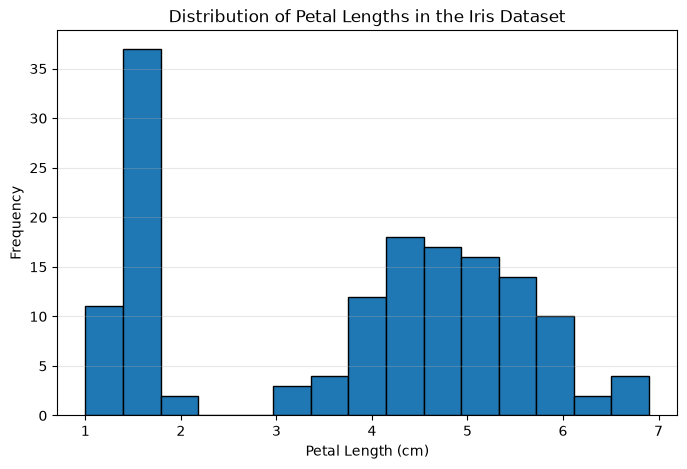

In [12]:
# Load the Iris dataset from sklearn
iris = load_iris(as_frame=True)

# Extract petal length data
petal_length = iris.data['petal length (cm)']

# Create histogram
plt.figure(figsize=(8, 5))
plt.hist(petal_length, bins=15, edgecolor='black')
plt.title('Distribution of Petal Lengths in the Iris Dataset')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.3)

plt.show()

To Do:

Calculate the mean and standard deviation of the petal lengths.

Generate x-values spanning the range of the data.

Calculate the corresponding values from a normal distribution with the same mean and standard deviation.

Overlay the normal curve on top of the histogram.

Mean Petal Length: 3.758 cm
Standard Deviation: 1.765 cm


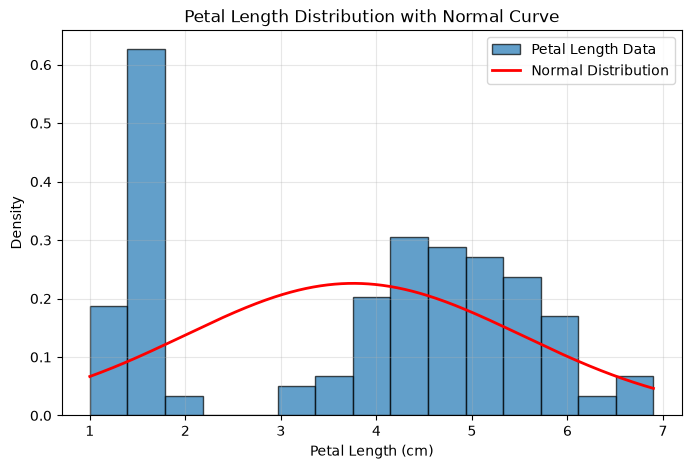

In [13]:
# Load Iris dataset
iris = load_iris(as_frame=True)

# Extract petal lengths
petal_length = iris.data['petal length (cm)']

# Calculate mean and standard deviation
mean = petal_length.mean()
std = petal_length.std()

print(f"Mean Petal Length: {mean:.3f} cm")
print(f"Standard Deviation: {std:.3f} cm")

# Plot histogram (density=True scales the histogram)
plt.figure(figsize=(8, 5))
plt.hist(
    petal_length,
    bins=15,
    density=True,
    edgecolor='black',
    alpha=0.7,
    label='Petal Length Data'
)

# Generate normal distribution curve
x = np.linspace(petal_length.min(), petal_length.max(), 1000)
y = norm.pdf(x, mean, std)

# Overlay normal distribution
plt.plot(
    x,
    y,
    color='red',
    linewidth=2,
    label='Normal Distribution'
)

plt.title('Petal Length Distribution with Normal Curve')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Density')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

Observations:


The histogram doen't follow a perfect normal distribution and the curve doesn't fit the dataset very well.

The distribution appears to have multiple peaks rather than a single bell shape. It is mmultimodal.

It would be safe to say that this is happening because the dataset contains measurements from three different iris species whose petal lengths differ substantially.

The setosa flowers form a distinct cluster at smaller petal lengths, while versicolor and virginica create additional clusters at larger values.


Might be better for us to look at the flowers individually

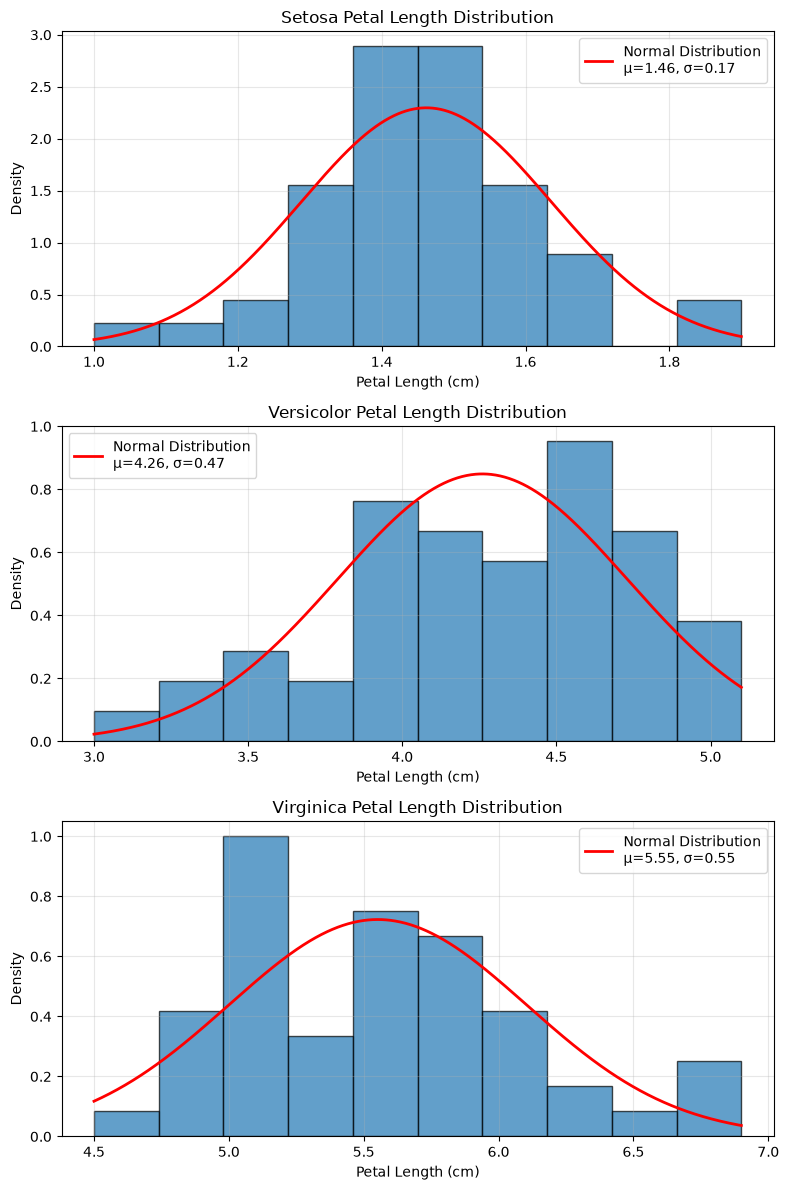

In [14]:
# Load Iris dataset
iris = load_iris(as_frame=True)

# Create DataFrame and add species names
df = iris.data.copy()
df['species'] = iris.target.map(
    dict(enumerate(iris.target_names))
)

# Create subplots
fig, axes = plt.subplots(3, 1, figsize=(8, 12))

# Loop through species
for ax, species in zip(axes, iris.target_names):

    # Select petal lengths for the species
    petal_lengths = df[df['species'] == species]['petal length (cm)']

    # Calculate mean and standard deviation
    mean = petal_lengths.mean()
    std = petal_lengths.std()

    # Histogram
    ax.hist(
        petal_lengths,
        bins=10,
        density=True,
        edgecolor='black',
        alpha=0.7
    )

    # Normal distribution curve
    x = np.linspace(
        petal_lengths.min(),
        petal_lengths.max(),
        1000
    )

    y = norm.pdf(x, mean, std)

    ax.plot(
        x,
        y,
        color='red',
        linewidth=2,
        label=f'Normal Distribution\nμ={mean:.2f}, σ={std:.2f}'
    )

    ax.set_title(f'{species.capitalize()} Petal Length Distribution')
    ax.set_xlabel('Petal Length (cm)')
    ax.set_ylabel('Density')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Mean and Stadard Devation results

In [15]:
# Load Iris dataset
iris = load_iris(as_frame=True)

# Create DataFrame
df = iris.data.copy()
df['species'] = iris.target.map(dict(enumerate(iris.target_names)))

# Complete dataset statistics
overall_mean = df['petal length (cm)'].mean()
overall_std = df['petal length (cm)'].std()

print("Complete Dataset")
print(f"Mean Petal Length: {overall_mean:.3f} cm")
print(f"Standard Deviation: {overall_std:.3f} cm")

# Species statistics
print("\nBy Species")
for species in iris.target_names:
    petal_lengths = df[df['species'] == species]['petal length (cm)']

    mean = petal_lengths.mean()
    std = petal_lengths.std()

    print(f"\n{species.capitalize()}")
    print(f"Mean Petal Length: {mean:.3f} cm")
    print(f"Standard Deviation: {std:.3f} cm")

Complete Dataset
Mean Petal Length: 3.758 cm
Standard Deviation: 1.765 cm

By Species

Setosa
Mean Petal Length: 1.462 cm
Standard Deviation: 0.174 cm

Versicolor
Mean Petal Length: 4.260 cm
Standard Deviation: 0.470 cm

Virginica
Mean Petal Length: 5.552 cm
Standard Deviation: 0.552 cm


Observations:

The histogram of petal length for the complete Iris dataset is multimodal, with several distinct peaks corresponding to the three species.

The fitted normal distribution does not provide a good representation of the overall data, as the combined distribution is not symmetric or bell-shaped. When the species are analysed separately, however, the distributions are more homogeneous and symmetric. 

The petal lengths of setosa, versicolor, and virginica each show a roughly bell-shaped pattern, with the normal distribution providing a reasonable fit in all three cases. 

The fit is particularly good for versicolor, while virginica exhibits slightly greater spread and minor asymmetry. 

Overall, a normal distribution is not an appropriate model for petal length across all species combined, but it is a reasonable estimate when each species is considered individually.

Draft prob 1 THE END

## Problem 2: Correlation Between Petal Length and Petal Width

Investigate the relationship between petal_length and petal_width in the Iris 
dataset.


Calculate the Pearson correlation coefficient between petal length and petal 
width using all 150 flowers.

Create an appropriate scatter plot showing the relationship between the two 
variables, and include a suitable line to help illustrate the relationship.

Calculate the Pearson correlation coefficient separately for each of the 
three species.

Create an appropriate plot showing the relationship between petal length and 
petal width for each species.

Report and compare the correlation coefficients.

Explain what the correlation coefficients tell you about the relationship 
between petal length and petal width, both for the dataset as a whole and 
within each species.

## Problem 3: Comparing Species Using t-Tests
Investigate whether the three iris species differ in their petal_length and 
petal_width.

For each pair of species:

setosa vs versicolor
setosa vs virginica
versicolor vs virginica

perform an independent-samples t-test for:

petal length,
petal width.

For each test:

State the null and alternative hypotheses.

Calculate the t-statistic and p-value using scipy.stats.

Use a significance level of  α = 0.05 to decide whether to reject the null hypothesis.

Summarise your results in an appropriate table.

Explain what the results tell you about differences between the three species.

## Problem 4: Comparing the Species Using ANOVA
The t-tests in Problem 3 require several separate comparisons between 
species. Instead, investigate differences in petal length and petal width 
using one-way analysis of variance (ANOVA).

For each variable:

State the null and alternative hypotheses for a one-way ANOVA.

Perform a one-way ANOVA comparing the three species using scipy.stats.

Report the F-statistic and p-value.

Use a significance level of  α = 0.05 to determine whether there is evidence that the species have different  population means.

Explain what the ANOVA result tells you and what it does not tell you about 
the individual species.
The t-tests in Problem 3 involved three pairwise comparisons. Explain why 
performing several separate hypothesis tests can increase the overall 
probability of making a type I error, and explain how ANOVA addresses this 
problem by testing the three group means simultaneously.


Finally, compare the conclusions from your t-tests with those from the ANOVA 
and explain why ANOVA is generally preferable when comparing more than two 
groups.